# BƯỚC 0 — DATASET AUDIT | Mushroom-44-clean

**Dự án:** Nghiên cứu ViT-B/16 để phân loại 44 loài nấm  
**Môi trường dự kiến:** Kaggle Notebook (tương thích đường dẫn notebook `ver3-done-15-10.ipynb`)  
**Mục đích:** Khóa manifest dữ liệu trước khi train; phát hiện lỗi ảnh, phân bố lớp, trùng SHA256 và ảnh gần trùng pHash liên-split, kiểm tra nhãn và provenance (nếu có).

> **Notebook này KHÔNG train model, KHÔNG thay đổi hoặc xóa ảnh gốc.** Tất cả kết quả được ghi dưới `/kaggle/working/`. Không được tự động xóa ảnh chỉ vì pHash giống nhau; các cặp nghi ngờ phải xem thủ công, đặc biệt nếu khác loài. Sau khi xử lý dữ liệu, chạy audit lại và đóng băng manifest.

**Lưu ý về test:** Tập test cũ đã được xem trong các thí nghiệm trước. Giữ lại để so sánh lịch sử, và ưu tiên xây dựng một *external test* độc lập, cùng bộ 44 nhãn, chưa từng dùng để ra quyết định nghiên cứu.

## 0.1. Cấu hình

- Thư mục dữ liệu phải có `train/<class>`, `valid/<class>`, `test/<class>`.
- `EXPECTED_CLASSES` được lấy trực tiếp từ notebook ViT-B/16 trước đó.
- `SOURCE_METADATA_CSV` là tùy chọn. Nếu có, tạo CSV chứa ít nhất `relative_path`, và các cột `source_id`, `specimen_id` nếu biết. Không tự đoán nguồn hoặc mẫu vật từ tên file.
- `PHASH_DISTANCE_MAX=4` chỉ là ngưỡng **sàng lọc** các cặp nghi vấn; không phải bằng chứng trùng mẫu vật.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform, warnings
from collections import Counter, defaultdict
from itertools import combinations
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError, ImageFile
from scipy.fft import dctn
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

DATA_DIR = Path('/kaggle/input/datasets/thoduynhunh/mushroom-44-clean')
OUTPUT_DIR = Path('/kaggle/working/Mushroom_44_clean_project/dataset_audit_step0')
SOURCE_METADATA_CSV = None  # vd: '/kaggle/input/my-provenance/mushroom_sources.csv'
SPLITS = ('train','valid','test')
NUM_CLASSES = 44
EXPECTED_COUNTS = {'train':9497, 'valid':2008, 'test':2065}
PHASH_DISTANCE_MAX = 4
CHECKPOINT_EVERY = 200
IMAGE_EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff','.ppm','.pgm'}
ALLOW_TRUNCATED = False  # Không che dấu file hỏng

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ImageFile.LOAD_TRUNCATED_IMAGES = ALLOW_TRUNCATED
assert DATA_DIR.is_dir(), f'Không tìm thấy dataset: {DATA_DIR}'
print('INPUT :', DATA_DIR)
print('OUTPUT:', OUTPUT_DIR)
print('Pillow:', Image.__version__ if hasattr(Image, '__version__') else 'available')

INPUT : /kaggle/input/datasets/thoduynhunh/mushroom-44-clean
OUTPUT: /kaggle/working/Mushroom_44_clean_project/dataset_audit_step0
Pillow: 13.0.0


In [2]:
EXPECTED_CLASSES = ['Agaricus augustus', 'Amanita amerirubescens', 'Amanita brunnescens', 'Amanita calyptroderma', 'Amanita flavoconia', 'Amanita muscaria', 'Amanita velosa', 'Armillaria mellea', 'Armillaria tabescens', 'Artomyces pyxidatus', 'Bolbitius titubans', 'Boletus pallidus', 'Boletus rex-veris', 'Cantharellus californicus', 'Cantharellus cinnabarinus', 'Cerioporus squamosus', 'Clitocybe nuda', 'Coprinellus micaceus', 'Coprinus comatus', 'Daedaleopsis confragosa', 'Entoloma abortivum', 'Flammulina velutipes', 'Ganoderma applanatum', 'Grifola frondosa', 'Hericium coralloides', 'Hygrophoropsis aurantiaca', 'Hypholoma fasciculare', 'Hypomyces lactifluorum', 'Ischnoderma resinosum', 'Laetiporus sulphureus', 'Lycoperdon perlatum', 'Lycoperdon pyriforme', 'Mycena haematopus', 'Omphalotus illudens', 'Omphalotus olivascens', 'Phlebia tremellosa', 'Pleurotus ostreatus', 'Pleurotus pulmonarius', 'Psilocybe pelliculosa', 'Retiboletus ornatipes', 'Sarcomyxa serotina', 'Stropharia ambigua', 'Suillus spraguei', 'Tricholoma murrillianum']
assert len(EXPECTED_CLASSES) == NUM_CLASSES and len(set(EXPECTED_CLASSES)) == NUM_CLASSES
print("Expected classes:", len(EXPECTED_CLASSES))

Expected classes: 44


## 0.2. Kiểm tra cấu trúc split và phân bố lớp

Nếu notebook báo số lượng khác kỳ vọng, **không sửa manifest cho khớp số đẹp**; kiểm tra phiên bản dataset, đường dẫn và lý do chênh lệch. Dùng tên lớp từ tên thư mục (không suy luận từ ảnh).

train: 44 lớp | thiếu=[] | thừa=[]
valid: 44 lớp | thiếu=[] | thừa=[]
test: 44 lớp | thiếu=[] | thừa=[]
Counts: {'train': 9497, 'valid': 2008, 'test': 2065}
Expected: {'train': 9497, 'valid': 2008, 'test': 2065}
Smallest class: 280 Largest class: 330


split,train,valid,test,total
class_name,,,,
Agaricus augustus,230,48,51,329
Amanita amerirubescens,230,49,49,328
Amanita brunnescens,214,45,47,306
Amanita calyptroderma,229,49,49,327
Amanita flavoconia,224,48,48,320
Amanita muscaria,229,48,49,326
Amanita velosa,198,42,43,283
Armillaria mellea,229,49,49,327
Armillaria tabescens,230,48,51,329


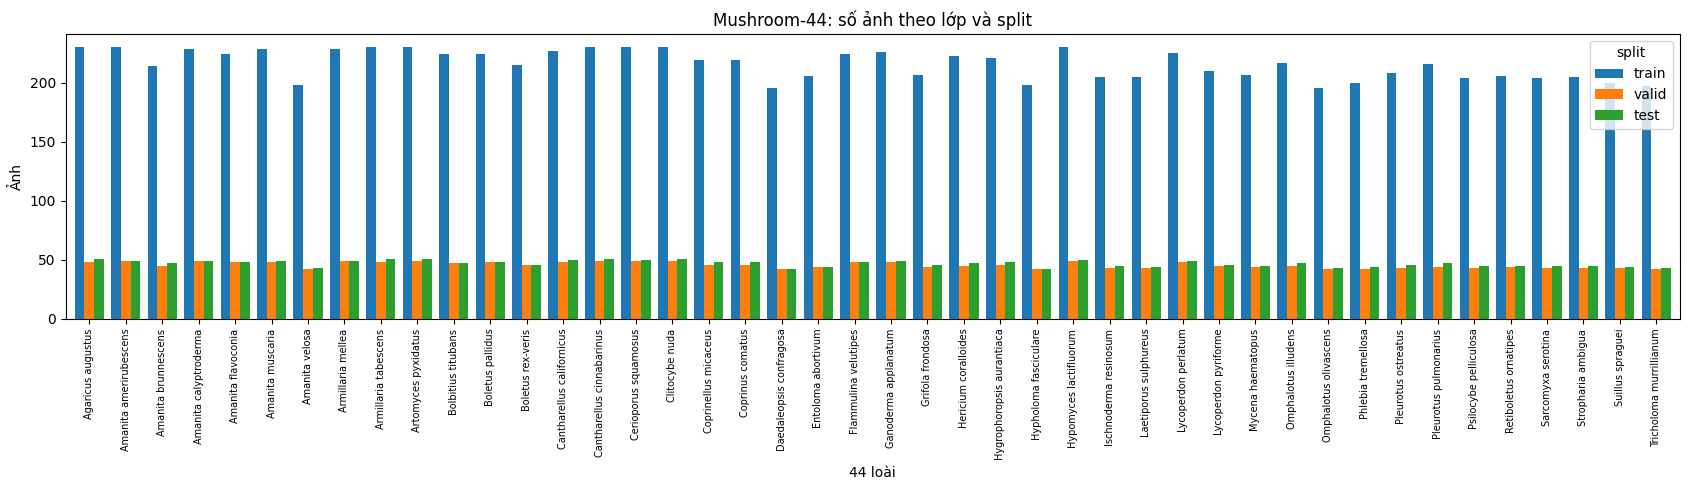

In [3]:
for split in SPLITS:
    assert (DATA_DIR / split).is_dir(), f'Thiếu split {split}'
classes_by_split = {sp: sorted(p.name for p in (DATA_DIR/sp).iterdir() if p.is_dir()) for sp in SPLITS}
for sp in SPLITS:
    missing = sorted(set(EXPECTED_CLASSES) - set(classes_by_split[sp]))
    extra = sorted(set(classes_by_split[sp]) - set(EXPECTED_CLASSES))
    print(f'{sp}: {len(classes_by_split[sp])} lớp | thiếu={missing} | thừa={extra}')
assert all(set(classes_by_split[sp]) == set(EXPECTED_CLASSES) for sp in SPLITS), 'Sai hoặc thiếu tên lớp. Kiểm tra dataset.'

# Chính sách duyệt ổn định theo thứ tự split / class / path
records=[]
unexpected_files=[]
for split in SPLITS:
    root=DATA_DIR/split
    for p in sorted(root.rglob('*'), key=lambda x:x.as_posix().casefold()):
        if not p.is_file(): continue
        rel=p.relative_to(DATA_DIR).as_posix()
        if p.suffix.lower() not in IMAGE_EXTENSIONS:
            unexpected_files.append({'split':split,'relative_path':rel,'extension':p.suffix.lower()})
            continue
        sub=p.relative_to(root).parts
        if len(sub) != 2:
            unexpected_files.append({'split':split,'relative_path':rel,'extension':p.suffix.lower(),'reason':'nested_path_not_imagefolder'})
            continue
        cls=sub[0]
        stat=p.stat()
        records.append({'split':split,'class_name':cls,'relative_path':rel,
                        'file_name':p.name,'file_size_bytes':stat.st_size,
                        'mtime_ns':stat.st_mtime_ns})
manifest0 = pd.DataFrame(records)
assert not manifest0.empty, 'Không tìm thấy ảnh!'
manifest0['class_id'] = manifest0['class_name'].map({c:i for i,c in enumerate(EXPECTED_CLASSES)}).astype(int)
counts = manifest0.groupby(['class_name','split']).size().unstack(fill_value=0).reindex(index=EXPECTED_CLASSES,columns=list(SPLITS),fill_value=0)
counts['total']=counts.sum(axis=1)
counts.to_csv(OUTPUT_DIR/'class_distribution.csv',encoding='utf-8-sig')
pd.DataFrame(unexpected_files).to_csv(OUTPUT_DIR/'unexpected_files.csv',index=False,encoding='utf-8-sig')
print('Counts:', manifest0['split'].value_counts().reindex(SPLITS).to_dict())
print('Expected:',EXPECTED_COUNTS)
for sp in SPLITS:
    if int((manifest0['split']==sp).sum()) != EXPECTED_COUNTS[sp]:
        warnings.warn(f'{sp} khác số lượng dự kiến. Cần điều tra, không tự xóa/đổi dữ liệu.')
print('Smallest class:',counts['total'].min(),'Largest class:',counts['total'].max())
display(counts.head(10))
fig,ax=plt.subplots(figsize=(17,5))
counts[list(SPLITS)].plot(kind='bar',ax=ax,width=.8)
ax.set(title='Mushroom-44: số ảnh theo lớp và split',ylabel='Ảnh',xlabel='44 loài')
ax.tick_params(axis='x',labelsize=7)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'class_distribution.png',dpi=180);plt.show()

## 0.3. Đọc ảnh, SHA256 và pHash (có checkpoint)

Với mỗi ảnh: `PIL.verify()` + `load()`, thu kích thước, mode, kích thước file, SHA256 và pHash 64-bit. Ảnh lỗi được ghi nhận; không bỏ qua âm thầm. Nếu dừng giữa chừng, chạy lại để tiếp tục từ checkpoint. File checkpoint chỉ được tái sử dụng khi đường dẫn, kích thước file và thời gian sửa khớp.

In [4]:
CHECKPOINT = OUTPUT_DIR/'image_audit_checkpoint.csv'
result_cols = ['split','class_name','class_id','relative_path','file_name','file_size_bytes','mtime_ns',
               'image_ok','error_type','image_mode','width','height','aspect_ratio','sha256','phash64']
old = pd.read_csv(CHECKPOINT,dtype={'phash64':'string','sha256':'string','relative_path':'string'}) if CHECKPOINT.exists() else pd.DataFrame(columns=result_cols)
old = old.drop_duplicates(subset=['relative_path'],keep='last')
cache = {str(r['relative_path']):r for r in old.to_dict('records')}

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def phash64_image(img):
    # pHash 8×8 dựa trên DCT, chuẩn hóa ảnh grayscale 32×32 (không cắt ảnh)
    resampling=getattr(Image,'Resampling',Image)
    a=np.asarray(img.convert('L').resize((32,32),resampling.LANCZOS),dtype=np.float64)
    coeff=dctn(a,norm='ortho')[:8,:8]
    bits=(coeff > np.median(coeff)).reshape(-1)
    return f'{int("".join("1" if v else "0" for v in bits),2):016x}'

def inspect_one(r):
    r=dict(r);path=DATA_DIR/r['relative_path']
    r.update({'image_ok':False,'error_type':'','image_mode':None,'width':None,'height':None,
              'aspect_ratio':None,'sha256':None,'phash64':None})
    try:
        with Image.open(path) as im: im.verify()
        with Image.open(path) as im:
            im.load()
            r['image_mode']=im.mode;r['width']=int(im.width);r['height']=int(im.height)
            if im.width<1 or im.height<1: raise ValueError('Kích thước ảnh bằng 0')
            r['aspect_ratio']=im.width/im.height
            r['phash64']=phash64_image(im)
        r['sha256']=sha256_file(path)
        r['image_ok']=True
    except Exception as e:
        r['error_type']=f'{type(e).__name__}: {str(e)[:220]}'
    return r

rows=[];processed=0
for row in tqdm(manifest0.to_dict('records'),desc='Kiểm tra ảnh và hash'):
    rel=row['relative_path']; prev=cache.get(rel)
    if prev and int(prev.get('file_size_bytes',-1))==int(row['file_size_bytes']) and int(prev.get('mtime_ns',-1))==int(row['mtime_ns']):
        item=prev
    else:
        item=inspect_one(row);processed+=1
    rows.append(item)
    if processed and processed%CHECKPOINT_EVERY==0:
        pd.DataFrame(rows,columns=result_cols).to_csv(CHECKPOINT,index=False,encoding='utf-8-sig')
manifest=pd.DataFrame(rows,columns=result_cols)
manifest.to_csv(CHECKPOINT,index=False,encoding='utf-8-sig')
manifest.to_csv(OUTPUT_DIR/'dataset_manifest.csv',index=False,encoding='utf-8-sig')
corrupted=manifest[~manifest['image_ok'].astype(bool)].copy()
corrupted.to_csv(OUTPUT_DIR/'corrupted_images.csv',index=False,encoding='utf-8-sig')
print('Kiểm tra:',len(manifest),'| ảnh lỗi:',len(corrupted),'| xử lý mới:',processed)
print('Non-RGB:',int((manifest['image_ok'] & (manifest['image_mode']!='RGB')).sum()))
display(corrupted.head(10))

Kiểm tra ảnh và hash:   0%|          | 0/13570 [00:00<?, ?it/s]

Kiểm tra: 13570 | ảnh lỗi: 0 | xử lý mới: 13570
Non-RGB: 0


,split,class_name,class_id,relative_path,file_name,file_size_bytes,mtime_ns,image_ok,error_type,image_mode,width,height,aspect_ratio,sha256,phash64


## 0.4. Trùng tuyệt đối (SHA256)

Xuất **cả trùng nội bộ split** và **trùng liên-split**, có cột `label_conflict`. Trùng file giữa train/valid/test là nguy cơ rò rỉ dữ liệu rõ ràng; không được train khi chưa điều tra.

In [5]:
valid=manifest[manifest.image_ok.astype(bool)].copy()
exact_rows=[]
for sha,group in valid.dropna(subset=['sha256']).groupby('sha256',sort=False):
    if len(group)<2: continue
    gs=group[['split','class_name','relative_path']].to_dict('records')
    for a,b in combinations(gs,2):
        exact_rows.append({'sha256':sha,'split_a':a['split'],'class_a':a['class_name'],'path_a':a['relative_path'],
                           'split_b':b['split'],'class_b':b['class_name'],'path_b':b['relative_path'],
                           'cross_split':a['split']!=b['split'],'label_conflict':a['class_name']!=b['class_name']})
exact=pd.DataFrame(exact_rows,columns=['sha256','split_a','class_a','path_a','split_b','class_b','path_b','cross_split','label_conflict'])
exact.to_csv(OUTPUT_DIR/'exact_duplicates_all.csv',index=False,encoding='utf-8-sig')
exact[exact['cross_split']].to_csv(OUTPUT_DIR/'exact_duplicates_cross_split.csv',index=False,encoding='utf-8-sig')
print('Exact all pairs:',len(exact),'| cross split:',int(exact.cross_split.sum()),'| nhãn xung đột:',int(exact.label_conflict.sum()))
display(exact[exact.cross_split].head(10))

Exact all pairs: 23 | cross split: 0 | nhãn xung đột: 0


,sha256,split_a,class_a,path_a,split_b,class_b,path_b,cross_split,label_conflict


## 0.5. Ảnh gần trùng liên-split bằng pHash (BK-tree)

Sử dụng **BK-tree** để tránh so từng cặp 13.570×13.570 theo cách ngây thơ. Hamming distance ≤ 4 là *near-duplicate candidate*, có thể bao gồm ảnh khác nhau trông gần giống hoặc bỏ sót ảnh cùng vật thể khi góc chụp thay đổi mạnh. Không tự xóa; đánh giá bằng hình ảnh và metadata.

In [6]:
class BKNode:
    __slots__=('value','items','children')
    def __init__(self,value,item): self.value=value;self.items=[item];self.children={}

class BKTree:
    def __init__(self): self.root=None
    def add(self,value,item):
        if self.root is None: self.root=BKNode(value,item);return
        node=self.root
        while True:
            d=(value^node.value).bit_count()
            if d==0: node.items.append(item);return
            child=node.children.get(d)
            if child is None: node.children[d]=BKNode(value,item);return
            node=child
    def query(self,value,radius):
        if self.root is None:return []
        found=[];stack=[self.root]
        while stack:
            node=stack.pop();d=(value^node.value).bit_count()
            if d<=radius:
                found.extend((d,item) for item in node.items)
            for cd,ch in node.children.items():
                if d-radius<=cd<=d+radius:stack.append(ch)
        return found

records_valid=valid.dropna(subset=['phash64']).to_dict('records')
by_split={sp:[r for r in records_valid if r['split']==sp] for sp in SPLITS}
near_rows=[]
for src_split,dst_split in [('train','valid'),('train','test'),('valid','test')]:
    tree=BKTree()
    for i,r in enumerate(by_split[src_split]):
        tree.add(int(str(r['phash64']),16),r)
    for r in tqdm(by_split[dst_split],desc=f'pHash: {src_split} x {dst_split}'):
        h=int(str(r['phash64']),16)
        for d,a in tree.query(h,PHASH_DISTANCE_MAX):
            # Duplicates SHA được báo riêng; vẫn giữ trong file này để đối chiếu.
            near_rows.append({'split_a':a['split'],'class_a':a['class_name'],'path_a':a['relative_path'],
                              'split_b':r['split'],'class_b':r['class_name'],'path_b':r['relative_path'],
                              'phash_distance':d,'sha256_equal':a['sha256']==r['sha256'],
                              'label_conflict':a['class_name']!=r['class_name'],'review_status':'UNREVIEWED'})
near=pd.DataFrame(near_rows,columns=['split_a','class_a','path_a','split_b','class_b','path_b',
                                     'phash_distance','sha256_equal','label_conflict','review_status'])
if len(near): near=near.sort_values(['phash_distance','label_conflict'],ascending=[True,False])
near.to_csv(OUTPUT_DIR/'near_duplicates_cross_split.csv',index=False,encoding='utf-8-sig')
print('Near cross-split candidate pairs:',len(near),'| label conflicts:',int(near.label_conflict.sum()))
display(near.head(12))

pHash: train x valid:   0%|          | 0/2008 [00:00<?, ?it/s]

pHash: train x test:   0%|          | 0/2065 [00:00<?, ?it/s]

pHash: valid x test:   0%|          | 0/2065 [00:00<?, ?it/s]

Near cross-split candidate pairs: 1 | label conflicts: 0


,split_a,class_a,path_a,split_b,class_b,path_b,phash_distance,sha256_equal,label_conflict,review_status
0,train,Cantharellus cinnabarinus,train/Cantharellus cinnabarinus/Cantharellus c...,test,Cantharellus cinnabarinus,test/Cantharellus cinnabarinus/Cantharellus ci...,4,False,False,UNREVIEWED


## 0.6. Kiểm tra nguồn ảnh / specimen ID (nếu có metadata)

Nếu tồn tại `source_id` hoặc `specimen_id`, kiểm tra một nguồn hoặc một mẫu vật có xuất hiện ở nhiều split hay không. Không có metadata thì kết luận **không thể xác minh sự độc lập ở cấp specimen** — không thay thế bằng pHash.

In [8]:
provenance=pd.DataFrame()
source_conflicts=[]
if SOURCE_METADATA_CSV:
    provenance=pd.read_csv(SOURCE_METADATA_CSV,dtype=str).fillna('')
    assert 'relative_path' in provenance.columns,'Metadata cần cột relative_path'
    assert not provenance['relative_path'].duplicated().any(),'Metadata trùng relative_path'
    provenance['relative_path']=provenance['relative_path'].str.replace('\\','/',regex=False)
    prov=manifest[['split','relative_path','class_name']].merge(provenance,on='relative_path',how='left',validate='one_to_one')
    for field in ('source_id','specimen_id'):
        if field in prov:
            tmp=prov[prov[field].notna() & (prov[field].astype(str).str.strip()!='')]
            for value,group in tmp.groupby(field):
                splits=sorted(group.split.unique())
                if len(splits)>1:
                    source_conflicts.append({'key_type':field,'key_value':value,'splits':';'.join(splits),
                                             'num_images':len(group),'paths_example':';'.join(group.relative_path.head(5))})
    print('Provenance metadata: đã nạp',len(provenance),'hàng')
else:
    print('CHƯA CÓ SOURCE_METADATA_CSV: không thể loại trừ rò rỉ ở cấp source/specimen.')
pd.DataFrame(source_conflicts,columns=['key_type','key_value','splits','num_images','paths_example']).to_csv(
    OUTPUT_DIR/'source_specimen_leakage.csv',index=False,encoding='utf-8-sig')
print('Cross-split source/specimen conflicts:',len(source_conflicts))

CHƯA CÓ SOURCE_METADATA_CSV: không thể loại trừ rò rỉ ở cấp source/specimen.
Cross-split source/specimen conflicts: 0


## 0.7. Kích thước ảnh, outlier và báo cáo cuối

Đánh dấu ảnh rất nhỏ hoặc tỷ lệ khung hình cực đoan để xem thủ công. Các cảnh báo này không chứng minh ảnh sai nhãn. Báo cáo `audit_summary.json` có `status=BLOCK_TRAINING` nếu có lỗi file, thiếu lớp, exact cross-split duplicates, nhãn xung đột hoặc xung đột provenance; các cặp pHash chưa duyệt có trạng thái `REVIEW_REQUIRED`.

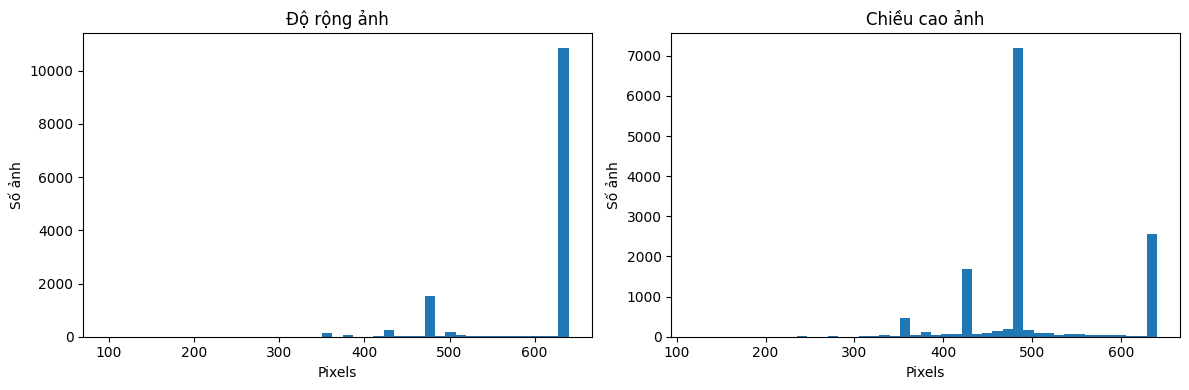

{
  "dataset_root": "/kaggle/input/datasets/thoduynhunh/mushroom-44-clean",
  "total_images": 13570,
  "split_counts": {
    "train": 9497,
    "valid": 2008,
    "test": 2065
  },
  "num_classes": 44,
  "expected_num_classes": 44,
  "corrupted_images": 0,
  "non_rgb_images": 0,
  "exact_duplicate_pairs_all": 23,
  "exact_duplicate_pairs_cross_split": 0,
  "exact_label_conflicts": 0,
  "phash_threshold": 4,
  "phash_candidate_pairs_cross_split": 1,
  "phash_candidate_label_conflicts": 0,
  "source_specimen_cross_split_conflicts": 0,
  "source_metadata_available": false,
  "size_outliers": 0,
  "note_test_history": "Tập test hiện tại đã được sử dụng trong các phiên bản nghiên cứu trước; không coi là blind external test.",
  "environment": {
    "python": "3.13.18",
    "pandas": "2.3.3",
    "pillow": "13.0.0",
    "numpy": "2.1.3"
  },
  "status": "REVIEW_REQUIRED"
}

Cần duyệt các file candidate bằng mắt trước khi khóa split. Tuyệt đối không tự động xóa ảnh.


In [9]:
valid['small_image']=(valid.width.astype(float)<96)|(valid.height.astype(float)<96)
valid['extreme_aspect']=(valid.aspect_ratio.astype(float)>3.5)|(valid.aspect_ratio.astype(float)<(1/3.5))
outliers=valid[valid.small_image|valid.extreme_aspect].copy()
outliers.to_csv(OUTPUT_DIR/'image_size_outliers.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(valid.width.astype(float),bins=45)
axes[0].set(title='Độ rộng ảnh',xlabel='Pixels',ylabel='Số ảnh')
axes[1].hist(valid.height.astype(float),bins=45)
axes[1].set(title='Chiều cao ảnh',xlabel='Pixels',ylabel='Số ảnh')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'resolution_distribution.png',dpi=180);plt.show()

def pyint(x):return int(x)
summary={
    'dataset_root':str(DATA_DIR),
    'total_images':len(manifest),
    'split_counts':{s:int((manifest.split==s).sum()) for s in SPLITS},
    'num_classes':len(set(manifest.class_name)),
    'expected_num_classes':NUM_CLASSES,
    'corrupted_images':len(corrupted),
    'non_rgb_images':int((valid.image_mode!='RGB').sum()),
    'exact_duplicate_pairs_all':len(exact),
    'exact_duplicate_pairs_cross_split':int(exact.cross_split.sum()),
    'exact_label_conflicts':int(exact.label_conflict.sum()),
    'phash_threshold':PHASH_DISTANCE_MAX,
    'phash_candidate_pairs_cross_split':len(near),
    'phash_candidate_label_conflicts':int(near.label_conflict.sum()),
    'source_specimen_cross_split_conflicts':len(source_conflicts),
    'source_metadata_available':bool(SOURCE_METADATA_CSV),
    'size_outliers':len(outliers),
    'note_test_history':'Tập test hiện tại đã được sử dụng trong các phiên bản nghiên cứu trước; không coi là blind external test.',
    'environment':{'python':sys.version.split()[0], 'pandas':pd.__version__, 'pillow':str(getattr(Image,'__version__','unknown')), 'numpy':np.__version__}
}
blocking=(len(corrupted)>0 or int(exact.cross_split.sum())>0 or int(exact.label_conflict.sum())>0 or len(source_conflicts)>0)
summary['status']='BLOCK_TRAINING' if blocking else ('REVIEW_REQUIRED' if len(near)>0 else 'PASS_WITH_CAVEATS')
(OUTPUT_DIR/'audit_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
(OUTPUT_DIR/'class_to_idx.json').write_text(json.dumps({c:i for i,c in enumerate(EXPECTED_CLASSES)},ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(summary,ensure_ascii=False,indent=2))
print('\nCần duyệt các file candidate bằng mắt trước khi khóa split. Tuyệt đối không tự động xóa ảnh.')

## 0.8. Tạo gói báo cáo gửi để kiểm tra

Sau khi chạy, tải ZIP tại đường dẫn được in ra và gửi lại. **Không cần gửi ảnh gốc** ở giai đoạn này; nếu một cặp nghi vấn cần xác minh, có thể gửi riêng vài ảnh đó kèm nhãn và nguồn.

In [10]:
import shutil
zip_path=shutil.make_archive(str(OUTPUT_DIR.parent/'Mushroom44_Step0_DatasetAudit'),'zip',root_dir=OUTPUT_DIR)
print('Báo cáo ZIP:',zip_path)
print('Files:',*[p.name for p in sorted(OUTPUT_DIR.iterdir())],sep='\n - ')

Báo cáo ZIP: /kaggle/working/Mushroom_44_clean_project/Mushroom44_Step0_DatasetAudit.zip
Files:
 - audit_summary.json
 - class_distribution.csv
 - class_distribution.png
 - class_to_idx.json
 - corrupted_images.csv
 - dataset_manifest.csv
 - exact_duplicates_all.csv
 - exact_duplicates_cross_split.csv
 - image_audit_checkpoint.csv
 - image_size_outliers.csv
 - near_duplicates_cross_split.csv
 - resolution_distribution.png
 - source_specimen_leakage.csv
 - unexpected_files.csv
